# Tome 8, Appendix G: Plane curves (Python companion)

Exercises first, solutions at the end. We build the Sylvester matrix by hand, watch Bézout's count $mn$ come out of a resultant, hunt for singular points, count the tangents from a point to a cubic, and see Cramer's paradox with our own eyes: nine points that impose only eight conditions. We use `numpy`, `sympy` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import itertools, math, random
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
x, y, z, t = sp.symbols('x y z t')
rng = np.random.default_rng(7); random.seed(7)

## Exercises

**P7.1 (★) The Sylvester matrix.** Write a function building $S(f,g)$ as in Section 7.1 and check, on random integer polynomials, that its determinant equals `sympy.resultant` and the product formula of Exercise 7.3.

**P7.2 (★) Bézout from a resultant.** For random curves $F,G$ of degrees $m,n\le4$, compute $\operatorname{Res}_z(F,G)$ and check that it is a nonzero form of degree $mn$ (Lemma 7.3). Then find all the complex intersection points numerically and check that there are $mn$ of them (Theorem 7.4). Redo it for the circle and cubic of Figure 7.2.

**P7.3 (★★) Singular points.** Find the singular points of the folium, the lemniscate and the curve $(x^2+y^2)^3=4x^2y^2z^2$ (a four-leaved rose) in $\mathbb P^2(\mathbb C)$, and compare with Theorem 7.6. Check the parametrisation of the lemniscate used in Exercise 7.7.

**P7.4 (★★) Six tangents.** For the smooth cubic $y^2z=x^3-xz^2$ and random points $Q$, solve $F=0$ together with the polar curve of Exercise 7.9, and count the tangents through $Q$. Draw the real ones.

**P7.5 (★★) Cramer's paradox.** (a) For the grid of Exercise 7.10, compute the dimension of the space of cubics through the nine points and through any eight of them. (b) Take two random cubics, compute their nine intersection points, fit a cubic through eight of them, and evaluate it at the ninth (Theorem 7.9). (c) Compare with nine *random* points.

## Solutions

### P7.1
**How to find it.** Row $r$ of the first block holds the coefficients of $x^{n-1-r}f$; row $r$ of the second those of $x^{m-1-r}g$. The product formula needs the roots, so compare numerically.

In [2]:
def sylvester(f, g):
    a, b = sp.Poly(f, x).all_coeffs(), sp.Poly(g, x).all_coeffs()
    m, n = len(a) - 1, len(b) - 1
    S = sp.zeros(m + n, m + n)
    for r in range(n):
        for k, c in enumerate(a): S[r, r + k] = c
    for r in range(m):
        for k, c in enumerate(b): S[n + r, r + k] = c
    return S

for trial in range(5):
    m, n = random.randint(1, 4), random.randint(1, 4)
    f = sum(random.randint(-5, 5) * x**k for k in range(m)) + random.choice([1, 2, 3]) * x**m
    g = sum(random.randint(-5, 5) * x**k for k in range(n)) + random.choice([1, -2]) * x**n
    d = sylvester(f, g).det()
    al = np.roots([float(c) for c in sp.Poly(f, x).all_coeffs()])
    be = np.roots([float(c) for c in sp.Poly(g, x).all_coeffs()])
    a0, b0 = sp.Poly(f, x).LC(), sp.Poly(g, x).LC()
    prod = float(a0)**n * float(b0)**m * np.prod([ai - bj for ai in al for bj in be])
    print(m, n, d, sp.resultant(f, g, x), round(prod.real, 6))
print(sylvester(x**2 + sp.Symbol('p') * x + sp.Symbol('q'), 2 * x + sp.Symbol('p')).det())   # Exercise ex:discriminant

3 2 1205 1205 1205.0
1 2 31 31 31.0
2 1 15 15 15.0
2 1 74 74 74.0
1 2 -5 -5 -5.0
-p**2 + 4*q


The three columns agree, and the last line is $4q-p^2$, the discriminant up to sign.

### P7.2
**How to find it.** First a random change of coordinates, so that $O=[0:0:1]$ is on neither curve and on no line joining two common points; then the resultant in $z$ is a form of degree $mn$. Its roots $[x_0:y_0]$ are the lines through $O$ containing intersection points; on each such line, solve for $z$ and keep the common roots.

In [3]:
def random_form(d):
    return sum(random.randint(-4, 4) * x**i * y**j * z**(d - i - j) for i in range(d + 1) for j in range(d + 1 - i)) + z**d

def intersections(F, G, T=None):
    # change coordinates by a random integer matrix T, so that O = [0:0:1] is on neither curve and in general position
    if T is None:
        T = sp.Matrix(3, 3, lambda i, j: random.randint(-3, 3) + (5 if i == j else 0))
    v = T * sp.Matrix([x, y, z])
    sub = {x: v[0], y: v[1], z: v[2]}
    F0, G0 = F, G
    F, G = sp.expand(F.xreplace(sub)), sp.expand(G.xreplace(sub))
    Rz = sp.Poly(sp.resultant(F, G, z), x, y)
    r = sp.Poly(Rz.as_expr().subs(y, 1), x)                    # roots x0 of R(x, 1): points [x0 : 1 : z0]
    pts = []
    for x0 in np.roots([complex(c) for c in r.all_coeffs()]):
        fz = np.roots([complex(c) for c in sp.Poly(F.subs({x: x0, y: 1}), z).all_coeffs()])
        gz = np.roots([complex(c) for c in sp.Poly(G.subs({x: x0, y: 1}), z).all_coeffs()])
        z0 = min(fz, key=lambda w: min(abs(w - v) for v in gz))
        w = np.array(T.evalf(), dtype=complex) @ np.array([x0, 1, z0])
        pts.append(tuple(w / w[np.argmax(abs(w))]))         # back to the original coordinates
    return Rz, pts

for m, n in [(1, 3), (2, 2), (2, 3), (3, 3), (3, 4)]:
    F, G = random_form(m), random_form(n)
    Rz, pts = intersections(F, G)
    worst = max(abs(complex(F.subs({x: p[0], y: p[1], z: p[2]}))) + abs(complex(G.subs({x: p[0], y: p[1], z: p[2]}))) for p in pts)
    print((m, n), 'deg R =', Rz.total_degree(), 'homogeneous:', Rz.is_homogeneous, ' points:', len(pts), ' max residual %.1e' % worst)

(1, 3) deg R = 3 homogeneous: True  points: 3  max residual 5.8e-15
(2, 2) deg R = 4 homogeneous: True  points: 4  max residual 5.7e-15


(2, 3) deg R = 6 homogeneous: True  points: 6  max residual 2.6e-14


(3, 3) deg R = 9 homogeneous: True  points: 9  max residual 3.6e-12


(3, 4) deg R = 12 homogeneous: True  points: 12  max residual 5.4e-06


In [4]:
F, G = x**2 + y**2 - sp.Rational(81, 25) * z**2, y * z**2 - x**3 + 3 * x * z**2      # circle of radius 1.8 and y = x^3 - 3x
r = sp.Poly(sp.resultant(F.subs(z, 1), G.subs(z, 1), y), x)
print(r.as_expr(), ' real roots:', [round(float(v), 4) for v in sp.real_roots(r)])

x**6 - 6*x**4 + 10*x**2 - 81/25  real roots: [-1.7775, -1.5543, -0.6515, 0.6515, 1.5543, 1.7775]


Always $mn$ points, and the circle meets the cubic in six real points, as in the figure. (For the circle we eliminated $y$ in the chart $z=1$, which is quicker here.)

### P7.3
**How to find it.** Solve $F_x=F_y=F_z=0$ with `sympy.solve` in the charts $z=1$ and $z=0,y=1$ (and the point $[1:0:0]$).

In [5]:
def singular_points(F):
    out = set()
    eqs = [sp.diff(F, v) for v in (x, y, z)]
    for sol in sp.solve([e.subs(z, 1) for e in eqs] + [F.subs(z, 1)], [x, y], dict=True):
        out.add((sp.nsimplify(sol[x]), sp.nsimplify(sol[y]), 1))
    for sol in sp.solve([e.subs({z: 0, y: 1}) for e in eqs] + [F.subs({z: 0, y: 1})], [x], dict=True):
        out.add((sp.nsimplify(sol[x]), 1, 0))
    if all(e.subs({x: 1, y: 0, z: 0}) == 0 for e in eqs): out.add((1, 0, 0))
    return out

for name, F in [('folium', x**3 + y**3 - 3 * x * y * z), ('lemniscate', (x**2 + y**2)**2 - z**2 * (x**2 - y**2)),
                ('four-leaved rose', (x**2 + y**2)**3 - 4 * x**2 * y**2 * z**2)]:
    d = sp.Poly(F, x, y, z).total_degree()
    S = singular_points(F)
    print(name, 'degree', d, 'bound', (d - 1) * (d - 2) // 2, 'singular:', S)
X = (t + t**3) / (1 + t**4); Y = (t - t**3) / (1 + t**4)
print('lemniscate parametrisation:', sp.simplify((X**2 + Y**2)**2 - (X**2 - Y**2)))

folium degree 3 bound 1 singular: {(0, 0, 1)}
lemniscate degree 4 bound 3 singular: {(I, 1, 0), (-I, 1, 0), (0, 0, 1)}
four-leaved rose degree 6 bound 10 singular: {(I, 1, 0), (-I, 1, 0), (0, 0, 1)}


lemniscate parametrisation: 0


The folium has one singular point and the lemniscate three, the bound for a quartic. The rose is a sextic with only three singular points, the origin and the two circular points, well under the bound $10$. But they are far from simple nodes: at the origin the lowest-degree part of the equation is $-4x^2y^2$, of degree $4$, so four branches pass through it, and such points "count" for more than one in the genus formula.

### P7.4
**How to find it.** The polar of $Q$ is $q_0F_x+q_1F_y+q_2F_z$, a conic. Intersect it with the cubic as in P7.2.

In [6]:
F = y**2 * z - x**3 + x * z**2
for trial in range(4):
    q = [random.randint(-5, 5) for _ in range(3)]
    if F.subs({x: q[0], y: q[1], z: q[2]}) == 0: continue
    G = sum(qi * sp.diff(F, v) for qi, v in zip(q, (x, y, z)))
    _, pts = intersections(F, sp.expand(G))
    real = [p for p in pts if max(abs(c.imag) for c in p) < 1e-7]
    print('Q =', q, ' tangency points:', len(pts), ' real:', len(real))

Q = [0, 4, -5]  tangency points: 6  real: 2


Q = [-4, -2, 4]  tangency points: 6  real: 2
Q = [-4, 2, 2]  tangency points: 6  real: 2


Q = [-1, 2, -3]  tangency points: 6  real: 2


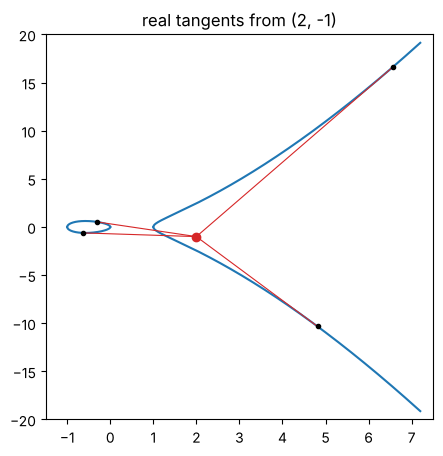

6 tangency points, of which real: [(np.float64(-0.6271441525546491), np.float64(-0.616832407397326)), (np.float64(4.814373219768739), np.float64(-10.33315448389464)), (np.float64(6.572593772370374), np.float64(16.65403289363065)), (np.float64(-0.3139112538639099), np.float64(0.5319570964726716))]


In [7]:
q = (2, -1, 1)                                  # the point (2, -1) of the affine plane
G = sum(qi * sp.diff(F, v) for qi, v in zip(q, (x, y, z)))
_, pts = intersections(F, sp.expand(G))
real = [((p[0] / p[2]).real, (p[1] / p[2]).real) for p in pts if abs(p[2]) > 1e-9 and max(abs((p[0] / p[2]).imag), abs((p[1] / p[2]).imag)) < 1e-7]
fig, ax = plt.subplots(figsize=(5, 5))
for sgn in (1, -1):
    for xs in (np.linspace(-1, 0, 400), np.linspace(1, 7.2, 600)):
        ax.plot(xs, sgn * np.sqrt(np.maximum(xs**3 - xs, 0)), 'C0')
for P in real:
    ax.plot(*zip(q[:2], P), 'C3', lw=0.8); ax.plot(*P, 'ko', ms=3)
ax.plot(*q[:2], 'C3o'); ax.set_xlim(-1.5, 7.5); ax.set_ylim(-20, 20); ax.set_title('real tangents from (2, -1)')
plt.show()
print(len(pts), 'tangency points, of which real:', real)

Six tangency points every time, as Exercise 7.9 predicts; how many are real depends on where $Q$ sits.

### P7.5
**How to find it.** A cubic has $10$ coefficients; passing through a point is the linear condition "monomial vector $\cdot$ coefficients $=0$". The space of cubics through the points is the null space of the matrix of monomial vectors.

In [8]:
mons = [(i, j, 3 - i - j) for i in range(4) for j in range(4 - i)]
def mvec(p): return [p[0]**a * p[1]**b * p[2]**c for a, b, c in mons]
grid = [(a, b, 1) for a in (-1, 0, 1) for b in (-1, 0, 1)]
M = sp.Matrix([mvec(p) for p in grid])
print('cubics through all nine grid points: dimension', 10 - M.rank())
print('through each set of eight:', {10 - sp.Matrix([mvec(p) for p in grid if p != q]).rank() for q in grid})
print('a basis:', [sp.factor(sum(c * x**a * y**b * z**cc for c, (a, b, cc) in zip(v, mons))) for v in M.nullspace()])

cubics through all nine grid points: dimension 2
through each set of eight: {2}
a basis: [y*(y - z)*(y + z), x*(x - z)*(x + z)]


In [9]:
def cubic_through(pts):
    A = np.array([mvec(p) for p in pts], dtype=complex)
    return np.linalg.svd(A)[2][-1].conj()                     # the null vector
for trial in range(3):
    F, G = random_form(3), random_form(3)
    _, pts = intersections(F, G)
    pts = [np.array(p, dtype=complex) / np.linalg.norm(np.array(p, dtype=complex)) for p in pts]
    c = cubic_through(pts[:8])
    rand = [np.array(rng.normal(size=3) + 1j * rng.normal(size=3)) for _ in range(9)]
    cr = cubic_through(rand[:8])
    print('ninth intersection point: %.1e   ninth random point: %.1e' % (abs(np.dot(c, mvec(pts[8]))), abs(np.dot(cr, mvec(rand[8])))))

ninth intersection point: 1.2e-15   ninth random point: 2.3e+00
ninth intersection point: 2.5e-17   ninth random point: 2.4e+00


ninth intersection point: 4.9e-16   ninth random point: 1.4e+00


Through the nine grid points passes a whole pencil (dimension $2$), spanned by $x(x-z)(x+z)$ and $y(y-z)(y+z)$, and dropping any one point does not make it bigger: the ninth point is free. For two random cubics the cubic through eight of their common points vanishes at the ninth to machine precision, while for random points it does not. That is Cayley–Bacharach, and the resolution of Cramer's paradox.